# Event simulation, deblurring with known answers, and reconstruction

Loads a clip from one of several sources into a common bundle (`evcam.sources.Clip`), simulates events from its frames (`evcam.simulate`), builds blurry / sharp / events triplets with a known contrast threshold to compare deblurring methods against ground truth, and reconstructs intensity from events alone (`evcam.reconstruct`). The default source is a procedurally rendered video, so the notebook runs without external data; sections whose data or weights are missing print `SKIPPED: <reason>`.

## Setup

In [1]:
import os, sys
if "google.colab" in sys.modules:
    REPO = "/content/event-perception"
    if not os.path.exists(REPO):
        !git clone https://github.com/allusson/event-perception.git {REPO}
    %cd {REPO}
    !pip install -q -e .
    sys.path.insert(0, REPO)
else:
    # local: assumes `pip install -e ".[deblur]"` was run from the repo root
    os.chdir(os.path.dirname(os.path.abspath("")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd())

In [2]:
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # must be set before torch is imported
import time
import numpy as np
import matplotlib.pyplot as plt

from evcam.sources import SOURCES, Clip, ensure_data_dirs, load_davis, load_reblur_clip, square_box, synthetic_video
from evcam.simulate import make_blur_triplet, simulate_events
from evcam.reconstruct import direct_integration, fit_scale_offset, highpass_filter, reconstruct_e2vid
from evcam.deblur import cmax_deblur, edi_deblur, edi_select_c, efnet_deblur
from evcam.representations import event_image, scer, scer_mask
from evcam.metrics import psnr, ssim
from evcam.viz import busiest_crop, show_images


def disp(img):
    # display only: linear intensity -> gamma 1/2.2
    return np.clip(img, 0, 1) ** (1 / 2.2)


T_NOTEBOOK = time.time()

## 0. Parameters

`SOURCE` selects the loader in `SOURCES`; `SOURCE_ARGS` holds the arguments of each loader. All later sections read only from the loaded `Clip`. `C_SIM` is the contrast threshold $c$ used to simulate events, `FORCE_SIMULATE` simulates events even for a source that has real events, `N_AVG` are the blur lengths of section 3 in frame periods, `HP_CUTOFF_HZ` is the cutoff $f_c$ of the high-pass filter in section 4, and `C_REAL` is the contrast threshold assumed for real events.

Video files store gamma-encoded values, but blur averages light in linear intensity and the event model uses the log of linear intensity, so `load_video` applies the inverse sRGB transfer function and every section works in linear intensity. Images are displayed with a $1/2.2$ power for visibility; all numbers are computed on linear intensity.

In [3]:
SOURCE = "synthetic"                        # "synthetic", "video", "davis" or "reblur"

VIDEO_PATH = "data/video_data/clip.mov"     # e.g. iPhone slow motion
CAPTURE_FPS = 240                           # true capture rate; the container often says 30
DAVIS_PATH = "data/davis_data/clip.aedat4"
REBLUR_SAMPLE = ("1-3-line-100", 3)         # (sequence, index) in the REBlur test split

SOURCE_ARGS = {
    "synthetic": dict(duration_s=0.5, fps=1000.0),
    "video": dict(path=VIDEO_PATH, capture_fps=CAPTURE_FPS, t_start_s=0.0, duration_s=1.0),
    "davis": dict(path=DAVIS_PATH, t_start_s=0.0, duration_s=2.0),
    "reblur": dict(seq=REBLUR_SAMPLE[0], idx=REBLUR_SAMPLE[1]),
}

C_SIM = 0.2
FORCE_SIMULATE = False
N_AVG = (4, 8, 16)
HP_CUTOFF_HZ = 2.0
C_REAL = 0.2
EFNET_WEIGHTS = "weights/EFNet-REBlur.pth"

ensure_data_dirs()                          # data/video_data/ and data/davis_data/ (gitignored)

## 1. Source

Loads the clip, shows four of its frames and, if it has events, the signed event count (ON minus OFF) over 10 ms in the middle of the event stream. If the selected source cannot be loaded, the synthetic source is used instead.

source synthetic, 346x260, 500 frames over 0.499 s, 1000 fps, no events
notes: rendered in linear intensity; frames are instants (no exposure)


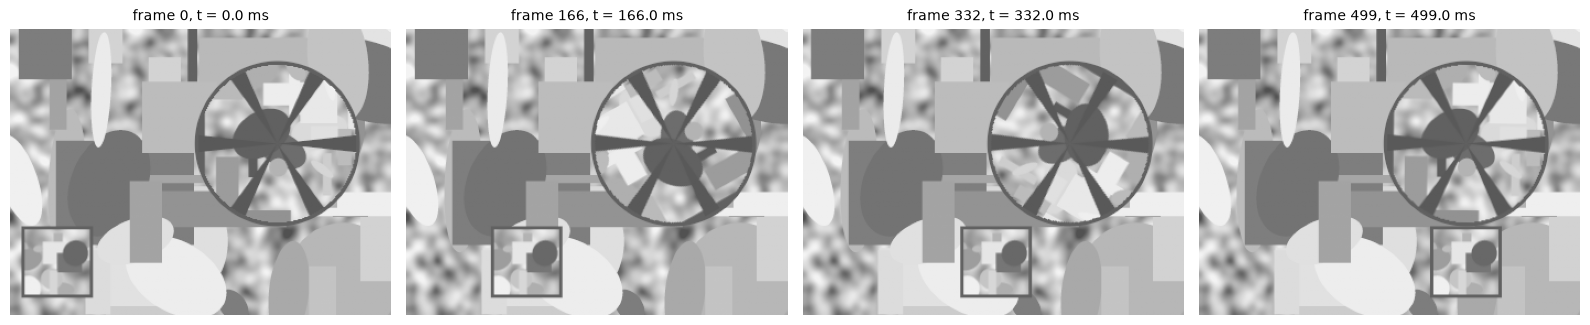

In [4]:
try:
    clip = SOURCES[SOURCE](**SOURCE_ARGS[SOURCE])
except (FileNotFoundError, OSError, RuntimeError, ValueError) as e:
    print(f"SKIPPED: source {SOURCE!r} could not be loaded ({e}); using the synthetic source")
    clip = synthetic_video(**SOURCE_ARGS["synthetic"])
print(clip.summary())
print("notes:", clip.meta.get("notes", "-"))

panels = []
if clip.n_frames:
    for i in np.linspace(0, clip.n_frames - 1, min(4, clip.n_frames)).astype(int):
        panels.append((disp(clip.frames[i]), f"frame {i}, t = {clip.frame_t[i] / 1e3:.1f} ms", "gray", 0, 1))
if clip.n_events:
    t_mid = int(np.median(clip.events["t"]))
    win = clip.events[(clip.events["t"] >= t_mid - 5000) & (clip.events["t"] < t_mid + 5000)]
    panels.append((event_image(win, (clip.shape[1], clip.shape[0], 2)), f"events, 10 ms at t = {t_mid / 1e3:.0f} ms",
                   "bwr", -3, 3))
fig, ax = plt.subplots(1, len(panels), figsize=(4 * len(panels), 3.2), squeeze=False)
for a, (img, title, cmap, lo, hi) in zip(ax[0], panels):
    a.imshow(img, cmap=cmap, vmin=lo, vmax=hi); a.set_title(title, fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

## 2. Event simulation

Needs at least two frames. Skipped for sources that already have real events, unless `FORCE_SIMULATE` is set.

Per pixel $\mathbf{x}$ the log intensity is

$$\ell(\mathbf{x}, t) = \log\big(I(\mathbf{x}, t) + \varepsilon\big)$$

$I$: linear intensity, $\varepsilon = 10^{-3}$. Each pixel keeps a reference level $\ell_\text{ref}(\mathbf{x})$, initialized from the first frame. Between frames $i$ and $i+1$ (times $t_i$, $t_{i+1}$) $\ell$ is linearly interpolated, and an event is emitted each time

$$\big|\ell(\mathbf{x}, t) - \ell_\text{ref}(\mathbf{x})\big| = c,$$

with polarity $p = \operatorname{sign}(\ell - \ell_\text{ref})$, at the crossing time

$$t_k = t_i + \frac{\ell_\text{ref} + p\,c - \ell_i}{\ell_{i+1} - \ell_i}\,(t_{i+1} - t_i),$$

after which $\ell_\text{ref} \leftarrow \ell_\text{ref} + p\,c$. $c$: contrast threshold, $\ell_i$, $\ell_{i+1}$: log intensity of the pixel in the two frames. Several crossings between two frames get evenly spaced times. The model is accurate when the motion between frames is small (high frame rate).

The cell simulates events at $c$ = `C_SIM` and shows the event image over 5 ms, the event rate over time (1 ms bins), and the event count for $c \in \{0.1, 0.2, 0.4\}$.

c = 0.2: 2,224,237 events (49.9% ON) simulated in 0.46 s


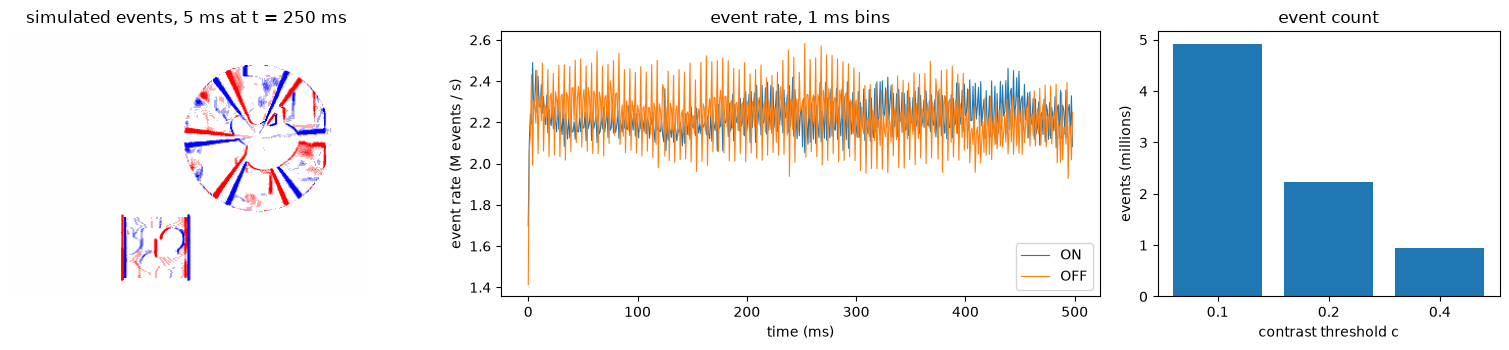

c = 0.1:  4,917,678 events   c x count = 491,768
c = 0.2:  2,224,237 events   c x count = 444,847
c = 0.4:    935,558 events   c x count = 374,223


In [5]:
sim = None
if clip.n_frames < 2:
    print(f"SKIPPED: event simulation needs at least 2 frames, the clip has {clip.n_frames}")
elif clip.events is not None and not FORCE_SIMULATE:
    print("SKIPPED: the source has real events (set FORCE_SIMULATE = True to simulate anyway)")
else:
    t0 = time.time()
    sim = simulate_events(clip, c=C_SIM)
    print(f"c = {C_SIM}: {sim.n_events:,} events ({np.mean(sim.events['p'] == 1):.1%} ON) "
          f"simulated in {time.time() - t0:.2f} s")

    t_mid = int(clip.frame_t[clip.n_frames // 2])
    win = sim.events[(sim.events["t"] >= t_mid - 2500) & (sim.events["t"] < t_mid + 2500)]
    edges = np.arange(clip.frame_t[0], clip.frame_t[-1] + 1000, 1000)
    counts = {c: (sim if c == C_SIM else simulate_events(clip, c=c)).n_events for c in (0.1, 0.2, 0.4)}

    fig, ax = plt.subplots(1, 3, figsize=(16, 3.6), gridspec_kw={"width_ratios": [1.2, 1.4, 0.8]})
    ax[0].imshow(event_image(win, (clip.shape[1], clip.shape[0], 2)), cmap="bwr", vmin=-3, vmax=3)
    ax[0].set_title(f"simulated events, 5 ms at t = {t_mid / 1e3:.0f} ms"); ax[0].axis("off")
    for pol, name in ((1, "ON"), (0, "OFF")):
        h, _ = np.histogram(sim.events["t"][sim.events["p"] == pol], edges)
        ax[1].plot(edges[:-1] / 1e3, h / 1e3, lw=0.8, label=name)      # events per ms -> per second / 1e6
    ax[1].set_xlabel("time (ms)"); ax[1].set_ylabel("event rate (M events / s)")
    ax[1].set_title("event rate, 1 ms bins"); ax[1].legend()
    ax[2].bar([str(c) for c in counts], [n / 1e6 for n in counts.values()])
    ax[2].set_xlabel("contrast threshold c"); ax[2].set_ylabel("events (millions)"); ax[2].set_title("event count")
    plt.tight_layout(); plt.show()
    for c, n in counts.items():
        print(f"c = {c}: {n:>10,} events   c x count = {c * n:,.0f}")

## 3. Deblurring with known answers

Needs frames and simulated events. A blurry frame is the average of the clip over an exposure of $n$ frame periods centred on frame $i$:

$$B = \frac{1}{T}\int_{t_i - T/2}^{t_i + T/2} I(t)\,dt, \qquad T = n\,\Delta t$$

$\Delta t$: frame period, $n$: `n_avg` $\in$ `N_AVG`. `make_blur_triplet` evaluates the integral with the trapezoid rule over the $n+1$ frames in the exposure; the sharp ground truth is frame $i$ and the events are the simulated events inside the exposure.

Methods, each a function of the triplet `Clip`:

- **EDI** (Pan et al., CVPR 2019), with $E(t)$ the signed event count of a pixel between $t_\text{ref} = t_i$ and $t$:

$$\hat L(t_\text{ref}) = \frac{B}{\frac{1}{T}\int \exp\big(c\,E(t)\big)\,dt}$$

  run with the true $c$, with $c$ chosen by `edi_select_c` (no ground truth; notebook 03), and for a sweep of $c$.
- **CMax + RL**: one blur vector per 64 px patch by contrast maximization, then Richardson-Lucy deconvolution (notebook 03). It assumes one translation per patch, which does not hold on the rotating disk.
- **EFNet** (Sun et al., ECCV 2022), pretrained on REBlur, if `weights/EFNet-REBlur.pth` and torch are available. EFNet was trained on real DAVIS data, not on simulated events.

With simulated events the true $c$ is known, so the gap between true-$c$ EDI and selected-$c$ EDI isolates the cost of choosing $c$. The remaining error of true-$c$ EDI comes from quantization: a change smaller than $c$ since a pixel's last event produces no event.

In [6]:
def exposure_of(clip, i=0):
    # (t_begin, t_end, t_ref) of frame i in microseconds
    t_a, t_b = clip.exposure[i]
    return int(t_a), int(t_b), int(clip.frame_t[i])


def edi_true_c(clip):
    t_a, t_b, t_ref = exposure_of(clip)
    return edi_deblur(clip.frames[0], clip.events, t_a, t_b, float(np.mean(clip.meta["c_true"])), t_ref=t_ref)


def edi_selected_c(clip):
    t_a, t_b, t_ref = exposure_of(clip)
    c, _ = edi_select_c(clip.frames[0], clip.events, t_a, t_b, t_ref=t_ref)
    clip.meta["c_selected"] = c
    return edi_deblur(clip.frames[0], clip.events, t_a, t_b, c, t_ref=t_ref)


def cmax_rl(clip):
    t_a, t_b, _ = exposure_of(clip)
    return cmax_deblur(clip.frames[0], clip.events, t_a, t_b)


efnet_model = efnet_device = None
if not os.path.exists(EFNET_WEIGHTS):
    print(f"SKIPPED: EFNet ({EFNET_WEIGHTS} not found)")
else:
    try:
        from evcam.deblur import pick_device
        from evcam.efnet_arch import load_efnet
        efnet_device = pick_device()
        efnet_model = load_efnet(EFNET_WEIGHTS, efnet_device)
        print(f"EFNet loaded on {efnet_device}")
    except ImportError as e:
        print(f"SKIPPED: EFNet ({e})")


def efnet(clip):
    t_a, t_b, _ = exposure_of(clip)
    S = scer(clip.events, t_a, t_b, clip.shape)
    return efnet_deblur(efnet_model, clip.frames[0], S, scer_mask(S), efnet_device)


METHODS = {"EDI, true c": edi_true_c, "EDI, selected c": edi_selected_c, "CMax + RL": cmax_rl}
if efnet_model is not None:
    METHODS["EFNet"] = efnet

EFNet loaded on mps


In [7]:
triplets, results, runtimes = {}, {}, {}
if sim is None or sim.n_frames < max(N_AVG) + 1:
    print("SKIPPED: deblurring with known answers needs frames and simulated events (section 2)")
else:
    center = sim.n_frames // 2
    for n in N_AVG:
        tr = make_blur_triplet(sim, center, n)
        triplets[n] = tr
        results[n] = {"blurry": tr.frames[0]}
        for name, method in METHODS.items():
            t0 = time.time()
            results[n][name] = method(tr)
            runtimes[name] = runtimes.get(name, 0) + time.time() - t0

    names = list(results[N_AVG[0]])
    print(f"centre frame {center}, true c = {C_SIM}; PSNR (dB) / SSIM against the sharp frame")
    fps = sim.meta.get("fps") or 1e3
    heads = [f"n_avg = {n} ({n / fps * 1e3:.0f} ms)" for n in N_AVG]
    print(f"{'method':<18}" + "".join(f"{h:>24}" for h in heads))
    for name in names:
        row = "".join(f"{psnr(results[n][name], triplets[n].meta['sharp']):>15.2f} / "
                      f"{ssim(results[n][name], triplets[n].meta['sharp']):.3f}" for n in N_AVG)
        print(f"{name:<18}{row}")
    print("selected c:", ", ".join(f"n_avg {n}: {triplets[n].meta['c_selected']:.3f}" for n in N_AVG))
    print("runtime over the three blur lengths:", ", ".join(f"{k} {v:.1f} s" for k, v in runtimes.items()))

centre frame 250, true c = 0.2; PSNR (dB) / SSIM against the sharp frame
method                    n_avg = 4 (4 ms)        n_avg = 8 (8 ms)      n_avg = 16 (16 ms)
blurry                      39.21 / 0.995          33.51 / 0.981          28.49 / 0.945
EDI, true c                 43.05 / 0.996          41.15 / 0.993          38.91 / 0.988
EDI, selected c             41.15 / 0.997          36.25 / 0.989          31.64 / 0.968
CMax + RL                   39.88 / 0.996          35.27 / 0.986          29.91 / 0.956
EFNet                       40.20 / 0.997          37.56 / 0.993          34.69 / 0.985
selected c: n_avg 4: 0.050, n_avg 8: 0.058, n_avg 16: 0.061
runtime over the three blur lengths: EDI, true c 0.0 s, EDI, selected c 0.1 s, CMax + RL 19.0 s, EFNet 1.3 s


PSNR of EDI against the sharp frame as a function of $c$, for each blur length. The dashed line is the true $c$, the dot the selected $c$. `edi_select_c` searches $c \in [0.05, 0.6]$.

n_avg 4: best c in sweep 0.16 (43.61 dB)
n_avg 8: best c in sweep 0.18 (41.21 dB)
n_avg 16: best c in sweep 0.20 (38.91 dB)


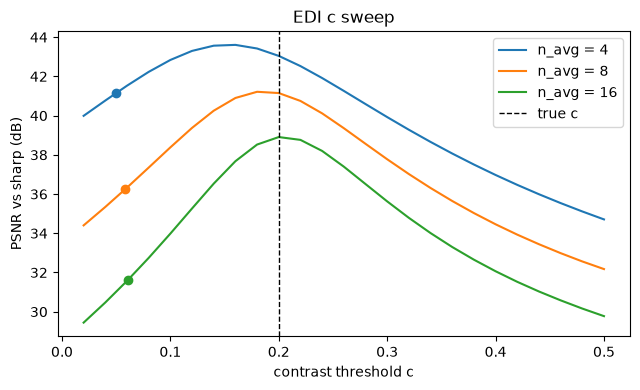

In [8]:
if triplets:
    cs = np.linspace(0.02, 0.5, 25)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    for n, tr in triplets.items():
        t_a, t_b, t_ref = exposure_of(tr)
        sharp = tr.meta["sharp"]
        curve = [psnr(edi_deblur(tr.frames[0], tr.events, t_a, t_b, c, t_ref=t_ref), sharp) for c in cs]
        line, = ax.plot(cs, curve, label=f"n_avg = {n}")
        c_sel = tr.meta["c_selected"]
        ax.plot(c_sel, psnr(results[n]["EDI, selected c"], sharp), "o", color=line.get_color())
        print(f"n_avg {n}: best c in sweep {cs[np.argmax(curve)]:.2f} ({max(curve):.2f} dB)")
    ax.axvline(C_SIM, color="k", ls="--", lw=1, label="true c")
    ax.set_xlabel("contrast threshold c"); ax.set_ylabel("PSNR vs sharp (dB)"); ax.set_title("EDI c sweep")
    ax.legend(); plt.tight_layout(); plt.show()

Zoomed crops for the longest blur. For the synthetic source the crops are the rotating disk and the translating square at the time of the sharp frame; for other sources, the region with the most events.

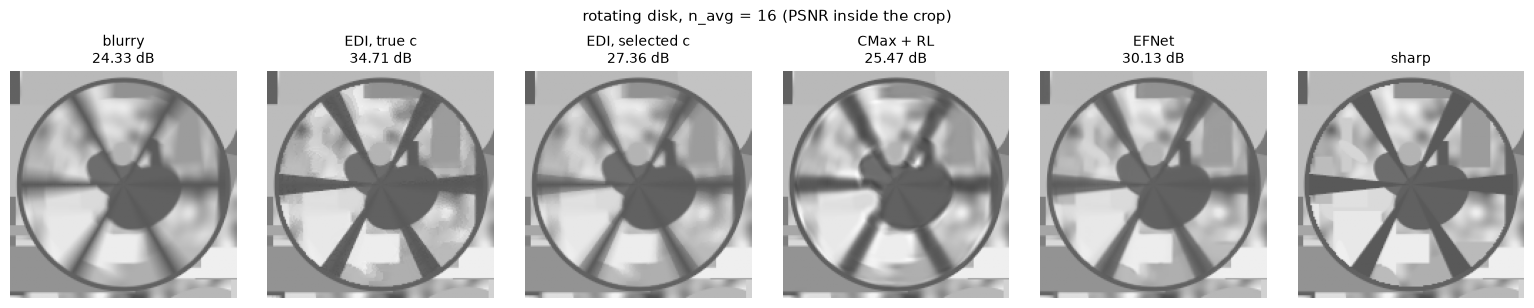

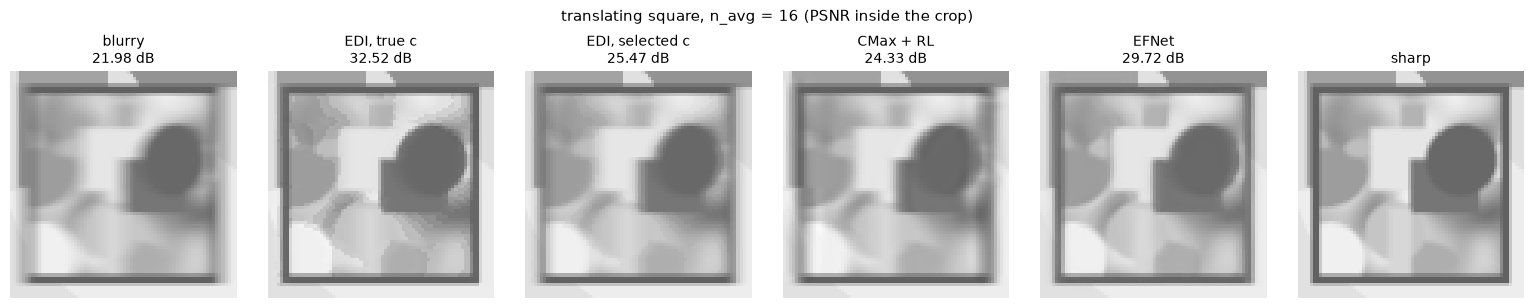

In [9]:
def to_crop(box, shape, pad=4):
    # (x0, y0, x1, y1) -> (y0, y1, x0, x1) for show_images, padded and clipped to the frame
    x0, y0, x1, y1 = box
    return max(y0 - pad, 0), min(y1 + pad, shape[0]), max(x0 - pad, 0), min(x1 + pad, shape[1])


if triplets:
    n = max(N_AVG)
    tr = triplets[n]
    if tr.meta.get("source") == "synthetic":
        crops = {"rotating disk": to_crop(tr.meta["disk_box"], tr.shape),
                 "translating square": to_crop(square_box(tr, tr.frame_t[0]), tr.shape)}
    else:
        crops = {"most events": busiest_crop(tr.events, tr.shape)}
    imgs = list(results[n].values()) + [tr.meta["sharp"]]
    for region, crop in crops.items():
        y0, y1, x0, x1 = crop
        ref = tr.meta["sharp"][y0:y1, x0:x1]
        titles = [f"{k}\n{psnr(v[y0:y1, x0:x1], ref):.2f} dB" for k, v in results[n].items()] + ["sharp"]
        fig = show_images([disp(im) for im in imgs], titles, crop=crop, figsize_per=(2.6, 3.1),
                          suptitle=f"{region}, n_avg = {n} (PSNR inside the crop)")
        fig.subplots_adjust(top=0.78); plt.show()

## 4. Reconstruction from events only

Needs events (simulated in section 2, or real). Both methods return a log intensity change $\hat\ell(\mathbf{x}, t)$ per pixel, starting from $\hat\ell = 0$.

**Direct integration.**

$$\hat\ell(\mathbf{x}, t) = c \sum_{k:\ \mathbf{x}_k = \mathbf{x},\ t_k \le t} p_k$$

$p_k = \pm 1$: polarity of event $k$. Any error in $c$, missed event or noise event stays in the sum, so $\hat\ell$ drifts.

**High-pass filter** (Scheerlinck et al., ACCV 2018), per pixel:

$$\frac{d\hat\ell}{dt} = \sum_k c\,p_k\,\delta(t - t_k) - \alpha\,\hat\ell, \qquad \alpha = 2\pi f_c$$

Between events $\hat\ell$ decays as $e^{-\alpha \Delta t}$; at each event it jumps by $c\,p_k$. $f_c$: cutoff frequency (`HP_CUTOFF_HZ`). Changes slower than $f_c$ are removed, including the drift and the static scene.

Neither method knows the starting log intensity of each pixel, so $\hat\ell$ shows the change since the start of the stream (direct integration) or over roughly the last $1/f_c$ (high-pass filter), not the scene itself.

**Comparison with ground truth.** Reconstructions are log intensity up to an unknown offset and scale, so before computing PSNR, $\hat I = a\,e^{\hat\ell} + b$ is fitted to the ground-truth frame by least squares over all pixels (`fit_scale_offset`). PSNR is reported over the whole frame and over the pixels whose ground-truth intensity changes during the clip (moving pixels); static pixels produce no events, so events carry no information about them. A constant image at the mean of the ground truth is the baseline.

2,224,237 events, 5 query times: direct integration 0.02 s, high-pass filter 0.02 s
SKIPPED: E2VID (E2VID is not vendored (rpg_e2vid is GPL-3.0); see reconstruct_e2vid's docstring.)


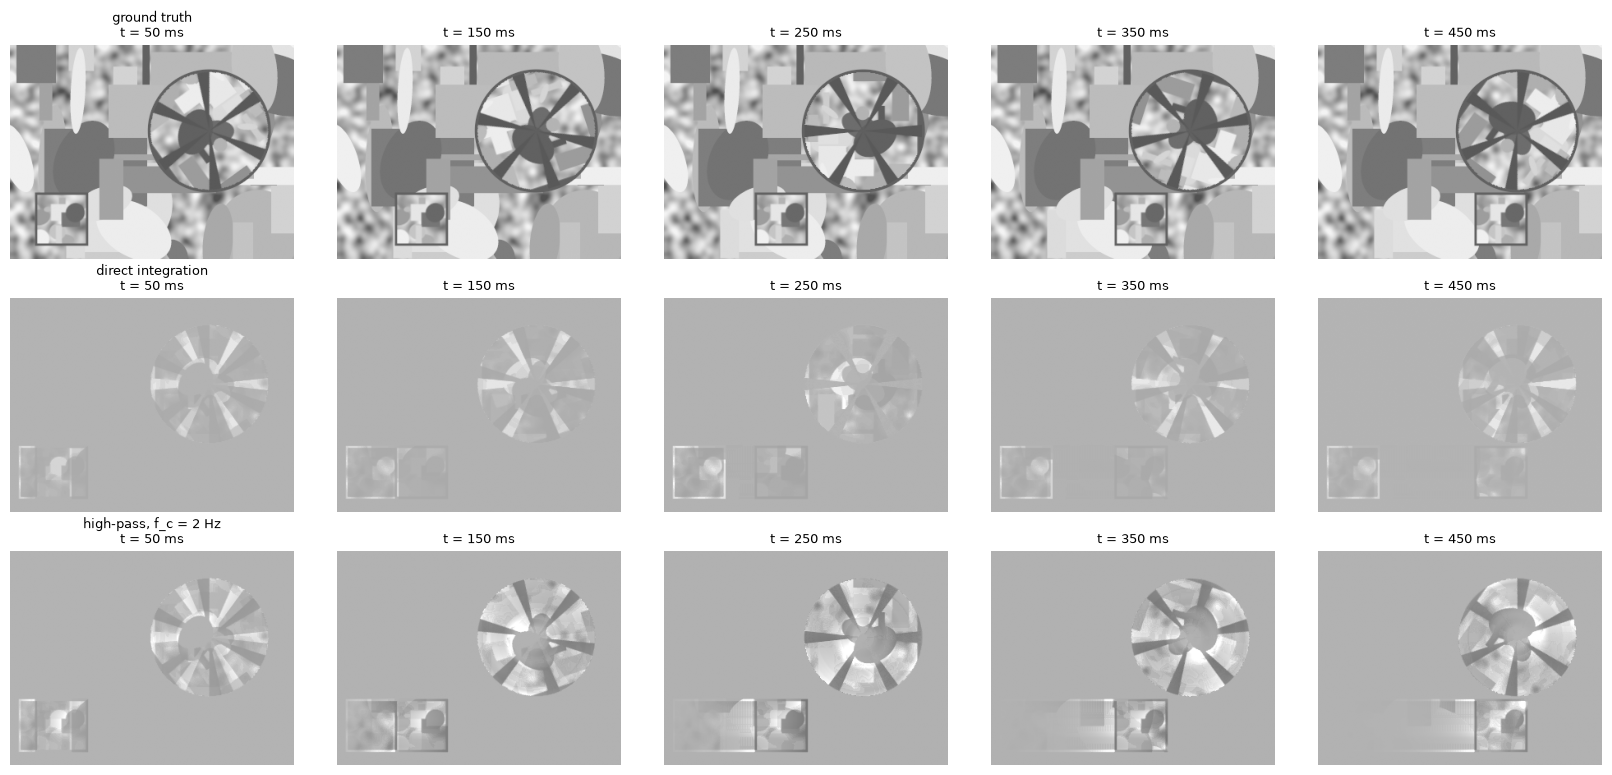

PSNR (dB) after the scale / offset fit, whole frame | moving pixels (38% of the frame)
method                             t = 50 ms        t = 150 ms        t = 250 ms        t = 350 ms        t = 450 ms
constant (mean of GT)         12.90 | 11.93    13.02 | 12.18    13.13 | 12.42    13.08 | 12.29    12.85 | 11.82
direct integration            13.10 | 12.36    13.23 | 12.64    13.36 | 12.95    13.30 | 12.82    13.06 | 12.27
high-pass, f_c = 2 Hz         13.29 | 12.78    13.82 | 14.15    14.17 | 15.26    14.11 | 15.04    13.82 | 14.15


In [10]:
ev_clip = sim if sim is not None else (clip if clip.n_events else None)
rec = {}
if ev_clip is None:
    print("SKIPPED: reconstruction needs events")
else:
    c_rec = float(np.mean(ev_clip.meta.get("c_true", C_REAL)))
    has_gt = ev_clip.n_frames > 1 and ev_clip.exposure is None       # instantaneous frames = ground truth
    if has_gt:
        q_idx = np.linspace(0.1 * ev_clip.n_frames, 0.9 * ev_clip.n_frames, 5).astype(int)
        t_q = ev_clip.frame_t[q_idx]
        gts = ev_clip.frames[q_idx]
        moving = (ev_clip.frames.max(axis=0) - ev_clip.frames.min(axis=0)) > 0.01
    else:
        t_q = np.linspace(ev_clip.events["t"][0], ev_clip.events["t"][-1], 5).astype(np.int64)
    t0 = time.time(); rec["direct integration"] = direct_integration(ev_clip.events, ev_clip.shape, c_rec, t_q)
    t1 = time.time(); rec[f"high-pass, f_c = {HP_CUTOFF_HZ:g} Hz"] = highpass_filter(ev_clip.events, ev_clip.shape, c_rec,
                                                                                     HP_CUTOFF_HZ, t_q)
    t2 = time.time()
    print(f"{ev_clip.n_events:,} events, {len(t_q)} query times: direct integration {t1 - t0:.2f} s, "
          f"high-pass filter {t2 - t1:.2f} s")
    try:
        rec["E2VID"] = reconstruct_e2vid(ev_clip.events, ev_clip.shape, t_q)
    except NotImplementedError as e:
        print(f"SKIPPED: E2VID ({e})")

    rows = ([("ground truth", [disp(g) for g in gts])] if has_gt else [])
    for name, L in rec.items():
        if has_gt:
            rows.append((name, [disp(fit_scale_offset(L[q], gts[q])[0]) for q in range(len(t_q))]))
        else:
            rows.append((name, [np.clip((L[q] + 1.5) / 3, 0, 1) for q in range(len(t_q))]))
    fig, ax = plt.subplots(len(rows), len(t_q), figsize=(3.3 * len(t_q), 2.6 * len(rows)), squeeze=False)
    for r, (name, imgs) in enumerate(rows):
        for q, img in enumerate(imgs):
            ax[r, q].imshow(img, cmap="gray", vmin=0, vmax=1); ax[r, q].axis("off")
            ax[r, q].set_title(f"{name}\nt = {t_q[q] / 1e3:.0f} ms" if q == 0 else f"t = {t_q[q] / 1e3:.0f} ms", fontsize=9)
    plt.tight_layout(); plt.show()

    if has_gt:
        def psnr_mask(img, ref, m):
            return float(10 * np.log10(1 / np.mean((img[m] - ref[m]) ** 2)))
        print(f"PSNR (dB) after the scale / offset fit, whole frame | moving pixels ({moving.mean():.0%} of the frame)")
        print(f"{'method':<26}" + "".join(f"{f't = {t / 1e3:.0f} ms':>18}" for t in t_q))
        base = [np.full_like(g, g.mean()) for g in gts]
        for name, imgs in [("constant (mean of GT)", base)] + \
                [(k, [fit_scale_offset(L[q], gts[q])[0] for q in range(len(t_q))]) for k, L in rec.items()]:
            print(f"{name:<26}" + "".join(f"{psnr(im, g):>9.2f} | {psnr_mask(im, g, moving):>5.2f}"
                                          for im, g in zip(imgs, gts)))

Drift. With the ideal simulated events, direct integration recovers the log intensity change exactly up to the quantization by $c$. The cell below simulates a second set of events with per-pixel thresholds drawn from $\mathcal N(c, 0.03^2)$ and $10^5$ noise events per second over the sensor, reconstructs both sets with the nominal $c$ at 50 times, and plots the RMS of $\hat\ell$ over the static pixels, where the true change is 0. The image on the right is direct integration of the non-ideal events at the last time.

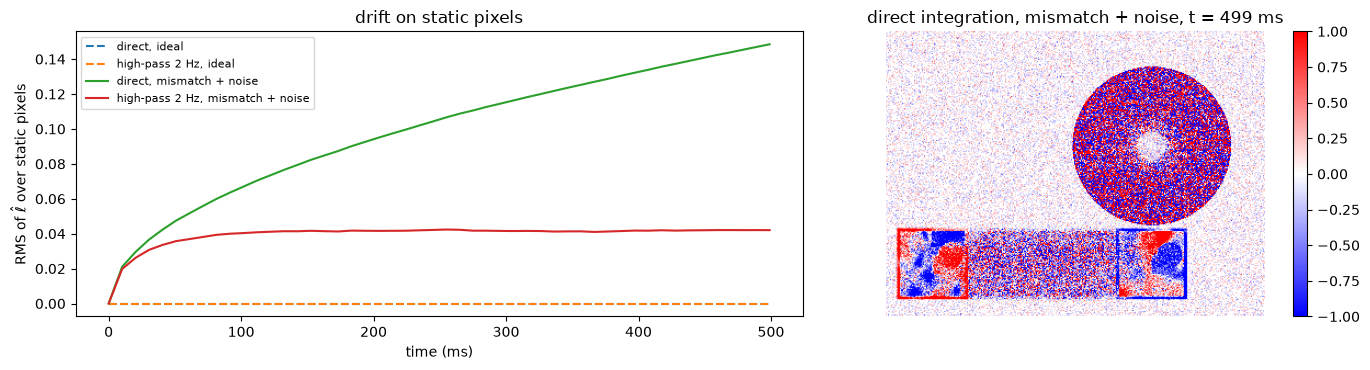

In [11]:
if ev_clip is None or sim is None or not has_gt:
    print("SKIPPED: the drift comparison needs simulated events and ground-truth frames")
else:
    noisy = simulate_events(clip, c=C_SIM, c_sigma=0.03, noise_rate_hz=1e5, seed=1)
    t_d = np.linspace(clip.frame_t[0], clip.frame_t[-1], 50).astype(np.int64)
    static = ~moving
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
    for label, ev, ls in (("ideal", sim.events, "--"), ("mismatch + noise", noisy.events, "-")):
        for name, L in (("direct", direct_integration(ev, clip.shape, C_SIM, t_d)),
                        (f"high-pass {HP_CUTOFF_HZ:g} Hz", highpass_filter(ev, clip.shape, C_SIM, HP_CUTOFF_HZ, t_d))):
            ax[0].plot(t_d / 1e3, np.sqrt(np.mean(L[:, static] ** 2, axis=1)), ls, label=f"{name}, {label}")
    D_last = direct_integration(noisy.events, clip.shape, C_SIM, t_d[-1:])[0]
    ax[0].set_xlabel("time (ms)"); ax[0].set_ylabel(r"RMS of $\hat\ell$ over static pixels")
    ax[0].set_title("drift on static pixels"); ax[0].legend(fontsize=8)
    im = ax[1].imshow(D_last, cmap="bwr", vmin=-1, vmax=1); plt.colorbar(im, ax=ax[1])
    ax[1].set_title(f"direct integration, mismatch + noise, t = {t_d[-1] / 1e3:.0f} ms"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

## 5. Real data

**(a) REBlur.** One test sample: the blurry and sharp DAVIS frames and the reconstruction from the events of the exposure at its midpoint, with $c$ = `C_REAL`. The events cover only the exposure, so $\hat\ell$ is the change since the exposure start. PSNR after the scale / offset fit against the sharp frame.

source reblur, 320x260, 1 frames over 0.000 s, 47,232 events over 0.046 s


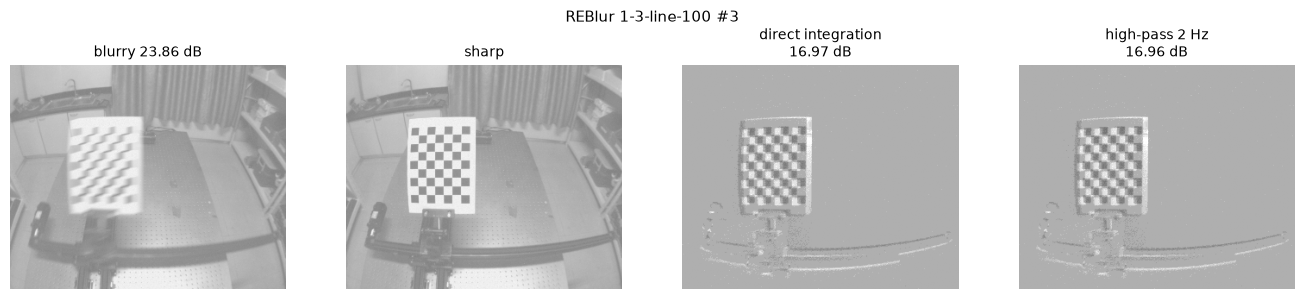

In [12]:
if not os.path.isdir("data/reblur/REBlur"):
    print("SKIPPED: REBlur not found (python scripts/download_data.py reblur)")
else:
    rb = load_reblur_clip(*REBLUR_SAMPLE)
    t_a, t_b, t_mid = exposure_of(rb)
    sharp = rb.meta["sharp"]
    imgs, titles = [disp(rb.frames[0]), disp(sharp)], [f"blurry {psnr(rb.frames[0], sharp):.2f} dB", "sharp"]
    for name, L in (("direct integration", direct_integration(rb.events, rb.shape, C_REAL, [t_mid])[0]),
                    (f"high-pass {HP_CUTOFF_HZ:g} Hz", highpass_filter(rb.events, rb.shape, C_REAL, HP_CUTOFF_HZ, [t_mid])[0])):
        fitted = fit_scale_offset(L, sharp)[0]
        imgs.append(disp(fitted)); titles.append(f"{name}\n{psnr(fitted, sharp):.2f} dB")
    print(rb.summary())
    show_images(imgs, titles, figsize_per=(3.4, 3.0), suptitle=f"REBlur {REBLUR_SAMPLE[0]} #{REBLUR_SAMPLE[1]}")
    plt.show()

**(b) Own DAVIS346 clip** at `DAVIS_PATH`, if present and its frames are APS frames (not DV Accumulator output). One frame whose exposure lies inside the event range, the frame with the most events in its exposure: EDI with selected $c$, EFNet, and the high-pass reconstruction at the frame time from all events up to then. No ground truth; qualitative only.

In [13]:
if not os.path.exists(DAVIS_PATH):
    print(f"SKIPPED: {DAVIS_PATH} not found")
else:
    dv = load_davis(DAVIS_PATH, **{k: v for k, v in SOURCE_ARGS["davis"].items() if k != "path"})
    if dv.frames is None:
        print(f"SKIPPED: {DAVIS_PATH}: {dv.meta['notes']}")
    else:
        t_ev = dv.events["t"]
        inside = np.flatnonzero((dv.exposure[:, 0] >= t_ev[0]) & (dv.exposure[:, 1] <= t_ev[-1]))
        if len(inside) == 0:
            print("SKIPPED: no frame exposure lies inside the event range")
        else:
            n_ev = [np.searchsorted(t_ev, e[1]) - np.searchsorted(t_ev, e[0]) for e in dv.exposure[inside]]
            i = inside[int(np.argmax(n_ev))]
            one = Clip(dv.frames[i:i + 1], dv.frame_t[i:i + 1], dv.exposure[i:i + 1], dv.events, dv.shape, dict(dv.meta))
            imgs, titles = [disp(one.frames[0])], [f"APS frame {i}, exposure {np.diff(one.exposure[0])[0] / 1e3:.1f} ms"]
            imgs.append(disp(edi_selected_c(one))); titles.append(f"EDI, selected c = {one.meta['c_selected']:.3f}")
            if efnet_model is not None:
                imgs.append(disp(efnet(one))); titles.append("EFNet")
            L = highpass_filter(dv.events, dv.shape, C_REAL, HP_CUTOFF_HZ, one.frame_t)[0]
            imgs.append(np.clip((L + 1.5) / 3, 0, 1)); titles.append(f"high-pass {HP_CUTOFF_HZ:g} Hz (log, unfitted)")
            show_images(imgs, titles, figsize_per=(3.6, 3.1), suptitle=DAVIS_PATH); plt.show()

SKIPPED: data/davis_data/clip.aedat4 not found


In [14]:
print(f"notebook runtime {time.time() - T_NOTEBOOK:.0f} s")

notebook runtime 26 s


## 6. How to add a source or method

- **Source:** write a function in `evcam/sources.py` that returns a `Clip` (frames in linear intensity with `frame_t`, and/or events in `EVENT_DTYPE`), add it to `SOURCES`, and add its arguments to `SOURCE_ARGS` in section 0.
- **Deblurring method:** write a function that takes a one-frame `Clip` (blurry frame, `exposure`, `events`) and returns the deblurred frame, and add it to `METHODS` in section 3.
- **Reconstruction method:** write a function `(events, shape, ..., t_query) -> (Q, H, W)` log intensity in `evcam/reconstruct.py` and add it to `rec` in section 4.